# Задача 1. Реакция пользователя

## 0. Подготовка

Необходимые импорты, настройка отображения графиков, подключение solution_utils

In [ ]:
import json
import os
import warnings
import joblib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import solution_utils as su

import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer

from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold

from sklearn.metrics import (
    accuracy_score, 
    balanced_accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score, 
    roc_auc_score, 
    average_precision_score,
    confusion_matrix
)


plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

BLUE, BLACK, OCHRE, GREY = "#0072CE", "#0F1418", "#C98A3C", "#9CA3AF"
REACTION_COLORS = {"negative": "#E41A1C", "neutral": GREY, "positive": "#4DAF4A"}
SEED = 42


def show_table(frame, digits=3, axis=0):
    # Таблица с заливкой: большие значения ярче (функция из семинара).
    numeric = frame.select_dtypes("number").columns
    return frame.style.background_gradient(cmap="Greens", subset=numeric, axis=axis).format(precision=digits, subset=numeric)



## 1. Чтение данных и первый взгляд

### 1.1. Читаем файл

In [26]:
# Ищем файл: сначала переменная окружения HW1_TRAIN, потом типичные места рядом с ноутбуком.
CANDIDATE_PATHS = [os.environ.get("HW1_TRAIN", ""), "hw1_train.jsonl", "dataset/hw1_train.jsonl", "hw1_data/hw1_train.jsonl"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p and os.path.exists(p)), None)
assert DATA_PATH is not None, f"не нашли hw1_train.jsonl, искали: {CANDIDATE_PATHS}. Нужно чтобы файл лежал в папке solution_hw1_BKZ!"
dialogs_raw = su.read_dialogs(DATA_PATH)
print("файл:", DATA_PATH, " диалогов:", len(dialogs_raw))

файл: hw1_data/hw1_train.jsonl  диалогов: 10000


### 1.2. Читаем файл с разбиением

In [27]:
CANDIDATE_PATHS = ["dialog_flags.csv", "dataset/dialog_flags.csv", "hw1_data/dialog_flags.csv"]
DATA_PATH = next((p for p in CANDIDATE_PATHS if p and os.path.exists(p)), None)
assert DATA_PATH is not None, f"dialog_flags.csv, искали: {CANDIDATE_PATHS}. Нужно чтобы файл лежал в папке solution_hw1_BKZ!"
flags_df = pd.read_csv(DATA_PATH)

In [28]:
texts_df = pd.DataFrame(dialogs_raw)
assert flags_df["dialog_id"].is_unique and texts_df["dialog_id"].is_unique
assert set(flags_df["dialog_id"]) == set(texts_df["dialog_id"]), "в файле флагов и в данных разные диалоги"

full_df = pd.concat([texts_df, flags_df], axis=1)

task1_df = full_df[full_df["use_reaction"] == 1].copy()

print(texts_df.columns)

Index(['dialog_id', 'language', 'n_user_turns', 'turns', 'labels'], dtype='object')


In [29]:
X_task1 = task1_df["turns"]
y_task1 = task1_df["reaction"]
groups_task1 = task1_df["group_id"]

print(f"Разбиение для задачи 1 готово! Объектов: {len(X_task1)}, Уникальных групп: {groups_task1.nunique()}")

Разбиение для задачи 1 готово! Объектов: 3000, Уникальных групп: 2982


### 1.3. Создаем train и test

In [30]:
CLASSES = ["negative", "neutral", "positive"]

In [31]:
gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)

# Получаем индексы для разбиения
train_idx, test_idx = next(gss.split(task1_df, y_task1, groups=groups_task1))

# Вырезаем train и test выборки
# Так как в turns лежат списки реплик, сначала превратим их в простые строки текста
def extract_text(turns_list):
    # Склеиваем все реплики пользователя в одну строку (или turn["text"] для всех реплик)
    return " ".join([turn.get("text", "") for turn in turns_list if isinstance(turn, dict)])

X_text_all = X_task1.apply(extract_text)

X_train, X_test = X_text_all.iloc[train_idx], X_text_all.iloc[test_idx]
y_train, y_test = y_task1.iloc[train_idx], y_task1.iloc[test_idx]

print(f"Обучение: {len(X_train)} строк, Тест: {len(X_test)} строк")
pd.DataFrame({"train": pd.Series(y_train).value_counts(normalize=True), "test": pd.Series(y_test).value_counts(normalize=True)}).loc[CLASSES].round(3)

Обучение: 2401 строк, Тест: 599 строк


,train,test
reaction,,
negative,0.309,0.304
neutral,0.592,0.588
positive,0.099,0.109


## 2.Модели

In [32]:
BASELINES = ["most_frequent", "stratified", "bow_logreg", "tfidf_logreg", "kirp_model"]
METRICS = ["macro_f1", "accuracy", "balanced_accuracy", "roc_auc_macro", "pr_auc_macro"]

### 2.1. Метрики

In [33]:
# y_true: (n,) из нулей и единиц, proba: (n,) — вероятности класса 1, groups: (n,) — группа объекта
# возвращает (число групп, 6): столбцы size, positive_share, precision, recall, f1, roc_auc
def metrics_by_group(y_true: np.ndarray, proba: np.ndarray, groups: pd.Series, threshold: float = 0.5) -> pd.DataFrame:
    df = pd.DataFrame({'yt': y_true, 'yp': (proba >= threshold).astype(int), 'pb': proba, 'gr': groups.values})
    
    # Внутренняя функция для расчета строки метрик одной группы
    def calc_metrics(sub):
        yt, yp, pb = sub['yt'].values, sub['yp'].values, sub['pb'].values
        return pd.Series({
            "size": len(sub),
            "positive_share": float(np.mean(yt)),
            "precision": float(precision_score(yt, yp, zero_division=0)),
            "recall": float(recall_score(yt, yp, zero_division=0)),
            "f1": float(f1_score(yt, yp, zero_division=0)),
            "roc_auc": float(roc_auc_score(yt, pb)) if len(np.unique(yt)) == 2 else np.nan
        })

    return df.groupby('gr', sort=True).apply(calc_metrics, include_groups=False)

### 2.2. Мое улучшение tfidf_logreg модели.
Как в семинаре обрабатываем слова английского и русского языков

In [34]:
stemmer_en = SnowballStemmer("english")
stemmer_ru = SnowballStemmer("russian")

stop_words_en = set(stopwords.words("english"))
stop_words_ru = set(stopwords.words("russian"))
all_stop_words = stop_words_en.union(stop_words_ru) # объединяем стоп-слова

WORD_REG = re.compile(r'[^\W\d_]+')

def smart_tokenizer(text: str) -> list[str]:
    text_lower = text.lower()
    raw_words = WORD_REG.findall(text_lower)
    
    result = []
    for word in raw_words:
        if (
            (len(word) < 2 or word in all_stop_words) and 
            (word != 'no' or 'ok' or 'yes' or 'not')
            ): continue
            
        # Проверяем, на каком языке слово (по первой букве)
        if 'а' <= word[0] <= 'я' or word[0] == 'ё':
            stemmed = stemmer_ru.stem(word) # пилим русские окончания
        else:
            stemmed = stemmer_en.stem(word) # пилим английские окончания
            
        result.append(stemmed)
    return result

### 2.3. Обучение моделек

In [35]:
baseline_models = {
    # 1. Всегда самый частый класс
    "most_frequent": DummyClassifier(strategy="most_frequent").fit(X_train, y_train),
    
    # 2. Пропорции классов
    "stratified": DummyClassifier(strategy="stratified", random_state=42).fit(X_train, y_train),
    
    # 3. Мешок слов (Count) + Логистическая регрессия
    "bow_logreg": make_pipeline(
        CountVectorizer(min_df=2, ngram_range=(1, 2)),
        LogisticRegression(C=10, max_iter=2000, class_weight="balanced")
    ).fit(X_train, y_train),
    
    # 4. TF-IDF + Логистическая регрессия
    "tfidf_logreg": make_pipeline(
        TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True),
        LogisticRegression(C=3, class_weight="balanced", max_iter=2000)
    ).fit(X_train, y_train),

    "kirp_model": make_pipeline(
        TfidfVectorizer(
            tokenizer=smart_tokenizer,
            token_pattern=None, 
            min_df=2,
            ngram_range=(1, 2),
            sublinear_tf=True
        ),
        LogisticRegression(
            C=10,
            class_weight="balanced",
            max_iter=2000
        )
    ).fit(X_train, y_train)
}


### 2.4. Подсчет метрик

In [36]:
# Список колонок для итоговой таблицы
# Динамически добавим поклассовые метрики для каждого из 3 классов
for cls in CLASSES:
    METRICS.extend([f"precision_{cls}", f"recall_{cls}"])

rows = []

# Цикл по всем моделям
for model_name in BASELINES:
    model = baseline_models[model_name]
    
    # Делаем предсказания (метки классов и полная матрица вероятностей)
    pred_labels = model.predict(X_test)
    pred_probas_matrix = model.predict_proba(X_test)
    
    # Вычисляем глобальные агрегированные метрики
    metrics_dict = {
        "macro_f1": f1_score(y_test, pred_labels, average="macro", zero_division=0),
        "accuracy": accuracy_score(y_test, pred_labels),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred_labels),
        "roc_auc_macro": roc_auc_score(y_test, pred_probas_matrix, multi_class="ovr", average="macro"),
        "pr_auc_macro": average_precision_score(pd.get_dummies(y_test), pred_probas_matrix, average="macro")
    }
    
    # Вычисляем Precision и Recall для каждого конкретного класса отдельно
    for cls_name in CLASSES:
        y_test_binary = (y_test == cls_name).astype(int)
        pred_labels_binary = (pred_labels == cls_name).astype(int)
        
        metrics_dict[f"precision_{cls_name}"] = precision_score(y_test_binary, pred_labels_binary, zero_division=0)
        metrics_dict[f"recall_{cls_name}"] = recall_score(y_test_binary, pred_labels_binary, zero_division=0)
        
    rows.append(metrics_dict)

baseline_table = pd.DataFrame(rows, index=BASELINES, columns=METRICS)
baseline_table.round(3)

,macro_f1,accuracy,balanced_accuracy,roc_auc_macro,pr_auc_macro,precision_negative,recall_negative,precision_neutral,recall_neutral,precision_positive,recall_positive
most_frequent,0.247,0.588,0.333,0.500,0.333,0.000,0.000,0.588,1.000,0.000,0.000
stratified,0.348,0.444,0.347,0.503,0.334,0.284,0.302,0.575,0.568,0.193,0.169
bow_logreg,0.534,0.651,0.518,0.684,0.524,0.599,0.484,0.693,0.810,0.415,0.262
tfidf_logreg,0.602,0.715,0.573,0.792,0.639,0.703,0.599,0.722,0.858,0.654,0.262
kirp_model,0.570,0.701,0.543,0.787,0.623,0.685,0.538,0.708,0.875,0.667,0.215


## 3. Матрица ошибок лучшей модели

In [37]:
BEST_NAME = baseline_table["macro_f1"].idxmax()

test_pred = baseline_models[BEST_NAME].predict(X_test)

cm = confusion_matrix(y_test, test_pred, labels=CLASSES)
pd.DataFrame(cm, index=[f"факт {c}" for c in CLASSES], columns=[f"предсказано {c}" for c in CLASSES])

,предсказано negative,предсказано neutral,предсказано positive
факт negative,109,72,1
факт neutral,42,302,8
факт positive,4,44,17


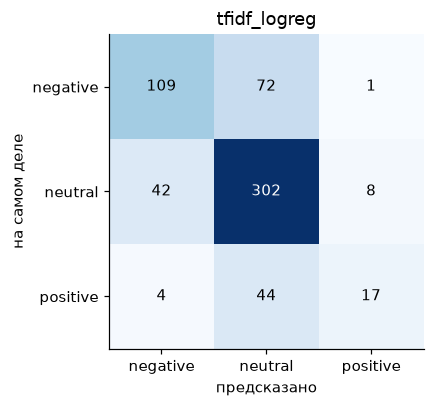

In [38]:
fig, ax = plt.subplots(figsize=(4.4, 3.8))
im = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(3))
ax.set_xticklabels(CLASSES)
ax.set_yticks(range(3))
ax.set_yticklabels(CLASSES)

ax.set_xlabel("предсказано")
ax.set_ylabel("на самом деле")
ax.set_title(BEST_NAME)
ax.grid(False)

for i in range(3):
    for j in range(3):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", color=color)

plt.tight_layout()
plt.show()


## 4. Разбор ошибок


In [39]:
best_model = baseline_models[BEST_NAME]

# Получаем бинарные прогнозы и полную матрицу вероятностей для X_test
test_pred = best_model.predict(X_test)
proba_test = best_model.predict_proba(X_test)

# Вырезаем именно те строки из task1_df, которые попали в тест по индексам test_idx
test_data_analysis = task1_df.iloc[test_idx].copy()
test_data_analysis["pred"] = test_pred

# Добавляем колонки с вероятностями для каждого из 3-х классов отдельно
for j, cls_name in enumerate(CLASSES):
    test_data_analysis[f"p_{cls_name}"] = proba_test[:, j]

print(f"Таблица для разбора ошибок успешно собрана! Доступно строк для анализа: {len(test_data_analysis)}")

Таблица для разбора ошибок успешно собрана! Доступно строк для анализа: 599


In [40]:
def short(text, n=120):
    # Вспомогательная функция для красивой обрезки длинных реплик ассистента
    return " ".join(text.split())[:n]

def show(df_sub):
    # Функция для вывода диалога на экран в читаемом  виде
    for idx, row in df_sub.iterrows():
        print(f"\n==== Диалог ID: {row.get('dialog_id', 'unknown')} | Факт: {row['reaction']} | Прогноз: {row['pred']} ====")
        
        # Перебираем реплики из turns
        turns = row['turns']
        if isinstance(turns, list):
            # Печатаем первые 4 реплики для контекста, чтобы не забивать экран
            for turn in turns[:4]:
                role = "Пользователь" if turn.get("role") == "user" else "Модель"
                print(f"[{role}]: {short(turn.get('text', ''))}")
        print(f"Вероятности классов -> Neg: {row['p_negative']:.2f} | Neu: {row['p_neutral']:.2f} | Pos: {row['p_positive']:.2f}")
        print("-" * 60)

In [41]:
groups_to_show = {
    "УПУЩЕННЫЙ НЕГАТИВ (Факт: negative, Прогноз: neutral)": (test_data_analysis["reaction"] == "negative") & (test_data_analysis["pred"] == "neutral"),
    "ЛОЖНАЯ ТРЕВОГА (Факт: neutral, Прогноз: negative)": (test_data_analysis["reaction"] == "neutral") & (test_data_analysis["pred"] == "negative"),
    "ИДЕАЛЬНО УГАДАННЫЙ НЕГАТИВ (Уверенность > 70%)": (test_data_analysis["reaction"] == "negative") & (test_data_analysis["p_negative"] > 0.70),
    "ИДЕАЛЬНО УГАДАННЫЙ ПОЗИТИВ (Уверенность > 70%)": (test_data_analysis["reaction"] == "positive") & (test_data_analysis["p_positive"] > 0.70)
}

In [42]:
# Случайным образом выбираем по 2 примера для каждой группы ошибок и выводим их
np.random.seed(42) # фиксируем сид для воспроизводимости отчета
for title, mask in groups_to_show.items():
    sub_df = test_data_analysis[mask]
    print(f"\nГРУППА: {title} (Всего таких ошибок в тесте: {len(sub_df)})")
    if len(sub_df) > 0:
        # Выбираем максимум 2 случайных примера
        sample_size = min(2, len(sub_df))
        show(sub_df.sample(n=sample_size))
    else:
        print("В этой категории ошибок нет! Модель сработала идеально.")



ГРУППА: УПУЩЕННЫЙ НЕГАТИВ (Факт: negative, Прогноз: neutral) (Всего таких ошибок в тесте: 72)

==== Диалог ID: dialog_id    de378ec5509
dialog_id    de378ec5509
Name: 124, dtype: object | Факт: negative | Прогноз: neutral ====
[Пользователь]: why is momentum before spare update? import torch from torch.optim.optimizer import Optimizer import math class Fusedbun
[Модель]: The momentum update before the sparse update in the provided code is a strategic choice based on the desire to leverage 
[Пользователь]: what happens when you put it first what are adavantages
[Модель]: Applying momentum before other operations like sparse updates or normalization in an optimization algorithm has several 
Вероятности классов -> Neg: 0.28 | Neu: 0.56 | Pos: 0.16
------------------------------------------------------------

==== Диалог ID: dialog_id    dd47a6ff091
dialog_id    dd47a6ff091
Name: 2523, dtype: object | Факт: negative | Прогноз: neutral ====
[Пользователь]: edit and improve the style of thi

## 5. Сохранение моделей

Для скрытого теста модели переобучаем на **всех** размеченных диалогах (dev + test): положительных всего ~300, лишние
данные важны. Параметры и пороги остаются выбранными на кросс-валидации, цифры в таблицах выше получены до переобучения.
Модели сохраняются в `artifacts/` рядом с `solution_utils.py`.

In [44]:
ARTIFACTS_DIR = "artifacts"
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

REACTION_ARTIFACTS = {
    "most_frequent": "most_frequent.joblib",
    "stratified": "stratified.joblib",
    "bow_logreg": "bow_logreg.joblib",
    "tfidf_logreg": "tfidf_logreg.joblib",
    "kirp_model": "kirp_model.joblib"

}

for name, model in baseline_models.items():
    if name in REACTION_ARTIFACTS:
        path = os.path.join(ARTIFACTS_DIR, REACTION_ARTIFACTS[name])
        # compress=3 сжимает файлы, чтобы они весили меньше и пролезали в лимиты гитхаба
        joblib.dump(model, path, compress=3)

# Считаем размеры получившихся файлов на диске (в МБ)
sizes = {
    f: round(os.path.getsize(os.path.join(ARTIFACTS_DIR, f)) / 1e6, 1) 
    for f in REACTION_ARTIFACTS.values()
}
print("размеры файлов, МБ:", sizes, " всего:", round(sum(sizes.values()), 1))


размеры файлов, МБ: {'most_frequent.joblib': 0.0, 'stratified.joblib': 0.0, 'bow_logreg.joblib': 9.8, 'tfidf_logreg.joblib': 10.1, 'kirp_model.joblib': 8.5}  всего: 28.4


### 5.1. Проверка: загружаем и тестируем инференс

In [45]:
print("\n--- Запуск проверки загруженных моделей ---")

# Эмулируем функцию init_reaction_models напрямую из файлов
loaded_models = {}
for name, filename in REACTION_ARTIFACTS.items():
    path = os.path.join(ARTIFACTS_DIR, filename)
    loaded_models[name] = joblib.load(path)

# Берем первые 200 диалогов из тестового набора данных X_test
sample_x = X_test.iloc[:200]

for name, model in loaded_models.items():
    # Прямой инференс модели на текстах без сторонних функций-заглушек
    answers = model.predict(sample_x)
    
    # Считаем пропорции ответов, чтобы убедиться, что логистическая регрессия выдает адекватные классы
    print(f"{name:20s} загружена, ответы на 200 диалогах: {pd.Series(answers).value_counts().to_dict()}")


--- Запуск проверки загруженных моделей ---
most_frequent        загружена, ответы на 200 диалогах: {'neutral': 200}
stratified           загружена, ответы на 200 диалогах: {'neutral': 112, 'negative': 68, 'positive': 20}
bow_logreg           загружена, ответы на 200 диалогах: {'neutral': 139, 'negative': 46, 'positive': 15}
tfidf_logreg         загружена, ответы на 200 диалогах: {'neutral': 145, 'negative': 45, 'positive': 10}
kirp_model           загружена, ответы на 200 диалогах: {'neutral': 149, 'negative': 44, 'positive': 7}
